
# Redes Bayesianas



## Instalación



In [ ]:

!pip -q install pgmpy pydot networkx



## Red del Estudiante (Student BN)

Variables (binarias para simplificar):
- **Difficulty (D):** fácil/difícil  
- **Intelligence (I):** baja/alta  
- **Grade (G):** mala/buena (depende de D e I)  
- **SAT (S):** malo/bueno (depende de I)  
- **Letter (L):** negativa/positiva (depende de G)

Estructura:
```
D → G → L
I → G
I → S
```



## Construcción del modelo en `pgmpy`


In [ ]:
from pgmpy.models import DiscreteBayesianNetwork as BayesianModel
from pgmpy.factors.discrete import TabularCPD

model = BayesianModel([('Difficulty','Grade'),
                       ('Intelligence','Grade'),
                       ('Intelligence','SAT'),
                       ('Grade','Letter')])

# Priors
cpd_D = TabularCPD('Difficulty', 2, [[0.6],[0.4]])                  # d0=facil, d1=dificil
cpd_I = TabularCPD('Intelligence', 2, [[0.7],[0.3]])                # i0=baja, i1=alta

# P(Grade | I, D) -> filas g0, g1 columnas (i,d)
cpd_G = TabularCPD('Grade', 2,
                   [[0.3, 0.05, 0.9, 0.5],   # g0 (mala)
                    [0.7, 0.95, 0.1, 0.5]],  # g1 (buena)
                   evidence=['Intelligence','Difficulty'],
                   evidence_card=[2,2])

# P(SAT | I)
cpd_S = TabularCPD('SAT', 2,
                   [[0.95, 0.2],   # s0 (malo)
                    [0.05, 0.8]],  # s1 (bueno)
                   evidence=['Intelligence'],
                   evidence_card=[2])

# P(Letter | G)
cpd_L = TabularCPD('Letter', 2,
                   [[0.9, 0.4],    # l0 (negativa)
                    [0.1, 0.6]],   # l1 (positiva)
                   evidence=['Grade'],
                   evidence_card=[2])

model.add_cpds(cpd_D, cpd_I, cpd_G, cpd_S, cpd_L)
assert model.check_model()
print("Modelo válido con", len(model.nodes()), "nodos y", len(model.edges()), "arcos.")

Modelo válido con 5 nodos y 4 arcos.



## Visualización rápida del grafo


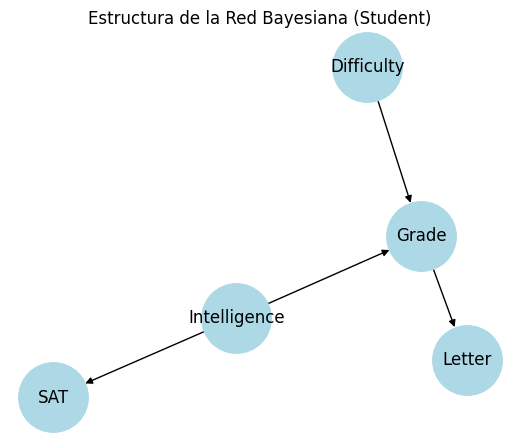

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

plt.figure(figsize=(5,4))
G = nx.DiGraph(model.edges())

pos = nx.spring_layout(G, seed=7)
nx.draw(G, pos, with_labels=True, node_size=2500, node_color="lightblue", arrows=True)
plt.title("Estructura de la Red Bayesiana (Student)")
plt.show()



## Inferencia exacta: Variable Elimination

Consultas típicas:  
- $P(G = \text{buena})$  
- $P(I = \text{alta} \mid S = \text{bueno})$
- $P(L = \text{positiva} \mid S=\text{bueno})$


In [ ]:
from pgmpy.inference import VariableElimination

infer = VariableElimination(model)

# 1) Marginal P(G=buena)
q1 = infer.query(variables=['Grade'])
print("P(Grade):")
print(q1)

# 2) Posterior P(I | S=bueno)
q2 = infer.query(variables=['Intelligence'], evidence={'SAT':1})
print("\nP(Intelligence | SAT=bueno):")
print(q2)

# 3) P(L | S=bueno)
q3 = infer.query(variables=['Letter'], evidence={'SAT':1})
print("\nP(Letter | SAT=bueno):")
print(q3)

P(Grade):
+----------+--------------+
| Grade    |   phi(Grade) |
+==========+==============+
| Grade(0) |       0.3620 |
+----------+--------------+
| Grade(1) |       0.6380 |
+----------+--------------+

P(Intelligence | SAT=bueno):
+-----------------+---------------------+
| Intelligence    |   phi(Intelligence) |
+=================+=====================+
| Intelligence(0) |              0.1273 |
+-----------------+---------------------+
| Intelligence(1) |              0.8727 |
+-----------------+---------------------+

P(Letter | SAT=bueno):
+-----------+---------------+
| Letter    |   phi(Letter) |
+===========+===============+
| Letter(0) |        0.7356 |
+-----------+---------------+
| Letter(1) |        0.2644 |
+-----------+---------------+



## Inferencia aproximada: muestreo (Gibbs/Forward Sampling)

Cuando las redes crecen, la inferencia exacta puede ser costosa. Podemos aproximar con **muestreo**.


In [ ]:

from pgmpy.sampling import BayesianModelSampling
import pandas as pd

sampler = BayesianModelSampling(model)
samples = sampler.forward_sample(size=5000, seed=42)
samples.head()


  0%|          | 0/5 [00:00<?, ?it/s]

,Difficulty,Grade,Intelligence,SAT,Letter
0,0,1,0,0,1
1,1,1,0,0,0
2,1,1,1,1,0
3,0,1,0,0,1
4,0,0,1,1,0


In [ ]:

# Aproximar P(Intelligence | SAT=bueno) por frecuencia en la muestra
subset = samples[samples['SAT']==1]
approx = subset['Intelligence'].value_counts(normalize=True).sort_index()
print("Aproximación por muestreo de P(Intelligence | SAT=bueno): ", approx.to_string())


Aproximación por muestreo de P(Intelligence | SAT=bueno):  Intelligence
0    0.151242
1    0.848758



## Aprendizaje de parámetros desde datos

Si conocemos la estructura pero no las CPTs, podemos estimarlas por **Máxima Verosimilitud (MLE)**.


In [ ]:

# Generamos un dataset sintético con el sampler y "olvidamos" las CPTs para reaprenderlas.
data = sampler.forward_sample(size=1000, seed=7)[['Difficulty','Intelligence','Grade','SAT','Letter']]

from pgmpy.estimators import MaximumLikelihoodEstimator, BayesianEstimator

learn_model = BayesianModel(model.edges())
learn_model.fit(data, estimator=MaximumLikelihoodEstimator)

for cpd in learn_model.get_cpds():
    print(cpd, "\n")


  0%|          | 0/5 [00:00<?, ?it/s]

+---------------+-------+
| Difficulty(0) | 0.611 |
+---------------+-------+
| Difficulty(1) | 0.389 |
+---------------+-------+ 

+--------------+--------------------+-----+--------------------+
| Difficulty   | Difficulty(0)      | ... | Difficulty(1)      |
+--------------+--------------------+-----+--------------------+
| Intelligence | Intelligence(0)    | ... | Intelligence(1)    |
+--------------+--------------------+-----+--------------------+
| Grade(0)     | 0.3129251700680272 | ... | 0.5045871559633027 |
+--------------+--------------------+-----+--------------------+
| Grade(1)     | 0.6870748299319728 | ... | 0.4954128440366973 |
+--------------+--------------------+-----+--------------------+ 

+-----------+---------------------+---------------------+
| Grade     | Grade(0)            | Grade(1)            |
+-----------+---------------------+---------------------+
| Letter(0) | 0.9030470914127424  | 0.40062597809076683 |
+-----------+---------------------+--------------


# Actividad

1. Con el modelo original, calcula $P(L=\text{positiva} \mid G=\text{buena})$ y compáralo con $P(L=\text{positiva})$.
2. Calcula $P(I=\text{alta} \mid L=\text{positiva})$. Interpreta el resultado.
3. Cambia la **dificultad** a $P(D=\text{difícil})=0.7$. ¿Cómo cambia $P(G=\text{buena})$?
4. Entrena parámetros con 500 datos sintéticos y compara con 5.000. ¿Qué cambia en las CPTs?


In [ ]:
import pandas as pd
from pgmpy.sampling import BayesianModelSampling
from pgmpy.inference import VariableElimination
from pgmpy.models import DiscreteBayesianNetwork as BayesianModel
from pgmpy.factors.discrete import TabularCPD
from pgmpy.estimators import MaximumLikelihoodEstimator, BayesianEstimator
